# Notebook 01: Data Quality Audit & Exploratory Data Analysis (EDA)
**Project:** Water Potability & Underwater Environmental Monitoring  
**Cadre:** Acyntra AIML Intern Cadre (Group C1)  
**Objective:** Verify cryptographic raw dataset integrity, audit sensor distributions, missingness mechanisms, and pairwise physicochemical correlations.

In [1]:
import os
import sys
from pathlib import Path

# Ensure project root is in sys.path and set as working directory
project_root = Path("..").resolve() if Path("..").resolve().name == "Water Potability" else Path(".").resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
os.chdir(project_root)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from src.data.loader import DataLoader
from src.data.audit import DataQualityAuditor

print("Environment initialized. Project root:", project_root)

Environment initialized. Project root: F:\Desktop\IIT G\Internship\Water Potability


## 1. Cryptographic Data Ingestion & Auto-Routing

In [2]:
data_path = Path("data/01_raw/water_potability.csv")
expected_hash = "904004BDE729BFE3D2E195F46343BCEEAD09E32A0EB95BB8184E7E20E029B2BF"
is_valid = DataLoader.verify_checksum(data_path, expected_hash)
print(f"SHA-256 Checksum Attestation: {is_valid}")

df, track, ts_col = DataLoader.load_dataset(data_path)
print(f"Auto-detected Track: {track} | Timestamp Column: {ts_col}")
print(f"Dataset Dimensions: {df.shape[0]} samples, {df.shape[1]} columns")
df.head()

2026-10-18 08:46:00 | INFO     | DataLoader:41 - Cryptographic SHA-256 checksum verified for data\01_raw\water_potability.csv
SHA-256 Checksum Attestation: True
2026-10-18 08:46:00 | INFO     | DataLoader:124 - Successfully loaded 3276 rows and 10 columns from data\01_raw\water_potability.csv
2026-10-18 08:46:00 | INFO     | DataLoader:91 - Auto-detected Track B (Static Tabular Water Potability).
Auto-detected Track: B | Timestamp Column: None
Dataset Dimensions: 3276 samples, 10 columns


,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


## 2. Sensor-Wise Quality Audit (Missingness, Bounds, Drift)

In [3]:
auditor = DataQualityAuditor()
audit_res = auditor.audit_tabular(df, target_col="Potability")
print(f"Total Observations: {audit_res['total_rows']}")
print(f"Duplicate Rows: {audit_res['duplicate_rows']}")
print(f"Potability Class Balance: {audit_res['target_distribution']}")
audit_res["sensor_table"]

Total Observations: 3276
Duplicate Rows: 0
Potability Class Balance: {0: 0.6098901098901099, 1: 0.3901098901098901}


,sensor_or_feature,missing_count,missing_pct,out_of_bounds_count,iqr_outlier_count,mean,std,min,max,half_split_ks_stat,half_split_p_val
0,ph,491,14.99,0,46,7.081,1.594,0.000,14.000,0.0224,0.8651
1,Hardness,0,0.00,0,83,196.369,32.880,47.432,323.124,0.0556,0.0127
2,Solids,0,0.00,0,47,22014.093,8768.571,320.943,61227.196,0.0391,0.1640
3,Chloramines,0,0.00,0,61,7.122,1.583,0.352,13.127,0.0537,0.0177
4,Sulfate,781,23.84,0,41,333.776,41.417,129.000,481.031,0.0551,0.0424
5,Conductivity,0,0.00,0,11,426.205,80.824,181.484,753.343,0.0183,0.9465
6,Organic_carbon,0,0.00,0,25,14.285,3.308,2.200,28.300,0.0232,0.7703
7,Trihalomethanes,162,4.95,0,33,66.396,16.175,0.738,124.000,0.0340,0.3279
8,Turbidity,0,0.00,0,19,3.967,0.780,1.450,6.739,0.0348,0.2745


## 3. Missing Value Analysis

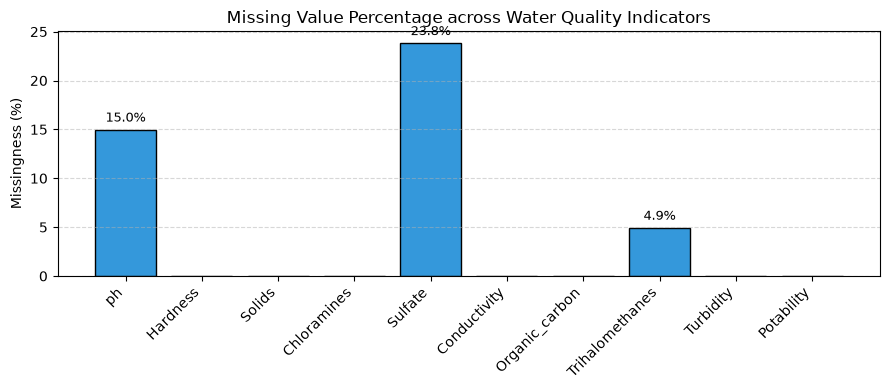

In [4]:
missing_pct = df.isna().mean() * 100
plt.figure(figsize=(9, 4))
bars = plt.bar(missing_pct.index, missing_pct.values, color="#3498db", edgecolor="black")
plt.title("Missing Value Percentage across Water Quality Indicators")
plt.ylabel("Missingness (%)")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)
for bar in bars:
    yval = bar.get_height()
    if yval > 0:
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.5, f"{yval:.1f}%", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Physicochemical Inter-Feature Correlation Matrix

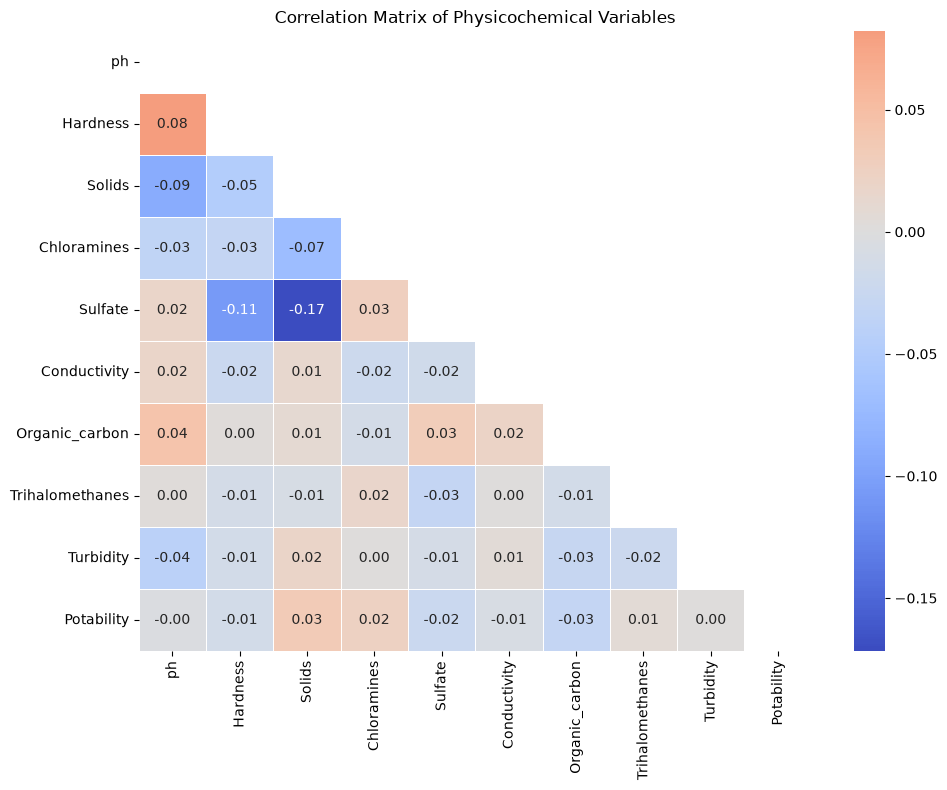

In [5]:
plt.figure(figsize=(10, 8))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Correlation Matrix of Physicochemical Variables")
plt.tight_layout()
plt.show()

## 5. Feature Distributions Stratified by Potability

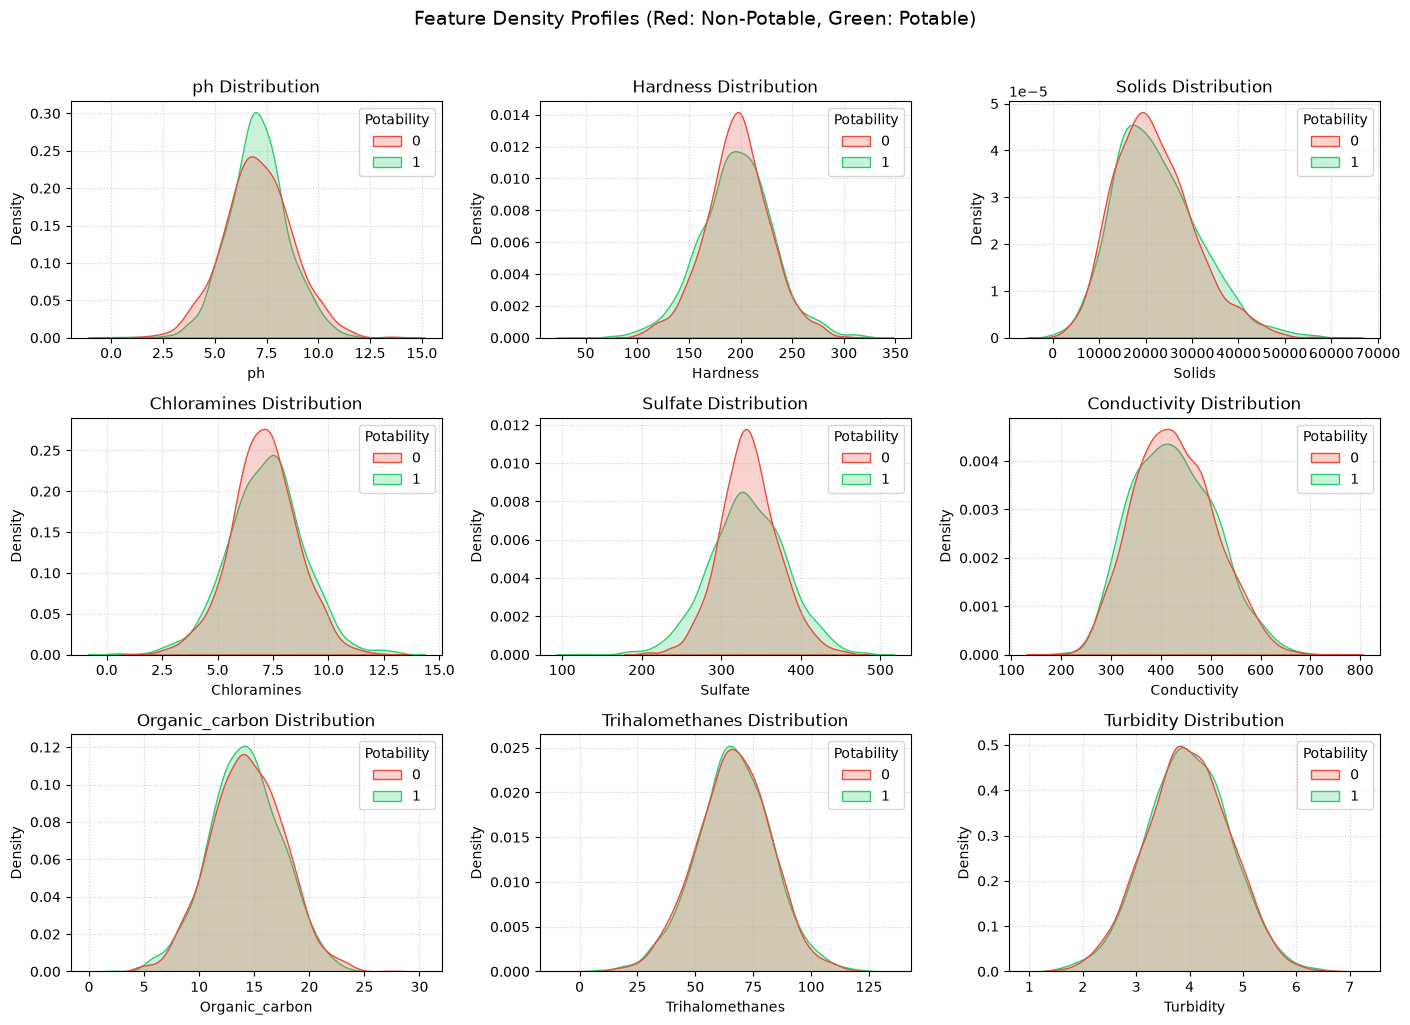

In [6]:
features = [c for c in df.columns if c != "Potability"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flatten(), features):
    sns.kdeplot(data=df, x=col, hue="Potability", common_norm=False, ax=ax, fill=True, palette=["#e74c3c", "#2ecc71"])
    ax.set_title(f"{col} Distribution")
    ax.grid(True, linestyle=":", alpha=0.6)
plt.suptitle("Feature Density Profiles (Red: Non-Potable, Green: Potable)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()